In [1]:
!pip install awkward uproot

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 698.7/698.7 kB 23.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 441.2/441.2 kB 20.9 MB/s eta 0:00:00


In [2]:
%pip install uproot

In [3]:
!pip install uproot awkward xgboost scikit-learn matplotlib pandas numpy


In [4]:
import uproot
import os

folder_path = "/content/drive/MyDrive/Dataset_HSF"

# List only ROOT files in the HSF Hackathon folder
root_files = [
    f for f in os.listdir(folder_path)
    if f.endswith(".root") and os.path.isfile(os.path.join(folder_path, f))
]

print("ROOT files found:", root_files)

ROOT files found: ['DY-train.root', 'Top-train.root', 'Higgs.root', 'WW-train.root']


In [5]:
import os

print(os.listdir("/content"))

['.config', 'drive', 'sample_data']


In [6]:
import uproot

file = uproot.open("/content/drive/MyDrive/Dataset_HSF/Higgs.root")

print(file)

<ReadOnlyDirectory '/' at 0x7b4cf782a7b0>


In [7]:
print(file.keys())

['Events;1']


In [8]:
import uproot

file = uproot.open("/content/drive/MyDrive/Dataset_HSF/Higgs.root")

print("Contents of the ROOT file:")
print(file.keys())

Contents of the ROOT file:
['Events;1']


In [9]:
tree = file["Events"]

print(tree)

<ROOT::RNTuple 'Events' (22 fields) at 0x7b4cf782a510>


In [10]:
print(tree.keys())

['Jet1_eta', 'Jet1_phi', 'Jet1_pt', 'Jet2_eta', 'Jet2_phi', 'Jet2_pt', 'Lepton1_eta', 'Lepton1_phi', 'Lepton1_pt', 'Lepton2_eta', 'Lepton2_phi', 'Lepton2_pt', 'PuppiMET_phi', 'PuppiMET_pt', 'dphill', 'jet_cat', 'mjj', 'mll', 'mth', 'mtw2', 'njet', 'ptll']


In [11]:
print("Number of events:", tree.num_entries)

Number of events: 21584


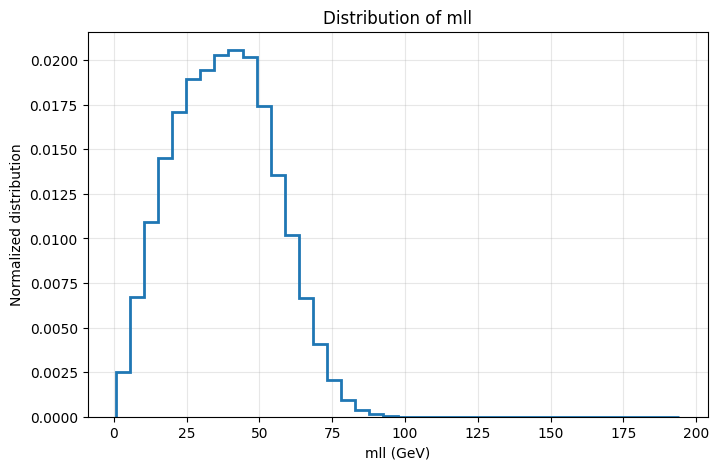

In [12]:

import numpy as np
import matplotlib.pyplot as plt

# Read the mll variable from your ROOT file
mll = tree["mll"].array(library="np")

# Remove invalid values
mll = np.asarray(mll, dtype=float)
mll = mll[np.isfinite(mll)]

# Draw the histogram
plt.figure(figsize=(8, 5))
plt.hist(mll, bins=40, density=True, histtype="step", linewidth=2)

plt.xlabel("mll (GeV)")
plt.ylabel("Normalized distribution")
plt.title("Distribution of mll")
plt.grid(alpha=0.3)
plt.show()


Total events: 21584
Valid events: 21584
Removed events: 0


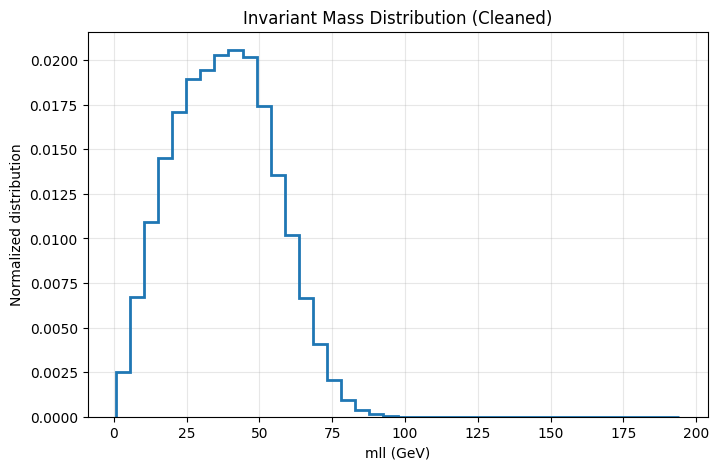

In [13]:

import numpy as np
import matplotlib.pyplot as plt

# Read the invariant mass
mll = tree["mll"].array(library="np")
mll = np.asarray(mll, dtype=float)

# Keep only finite, positive values
valid_mll = mll[np.isfinite(mll) & (mll > 0)]

print("Total events:", len(mll))
print("Valid events:", len(valid_mll))
print("Removed events:", len(mll) - len(valid_mll))

# Plot the cleaned histogram
plt.figure(figsize=(8, 5))
plt.hist(
    valid_mll,
    bins=40,
    density=True,
    histtype="step",
    linewidth=2
)

plt.xlabel("mll (GeV)")
plt.ylabel("Normalized distribution")
plt.title("Invariant Mass Distribution (Cleaned)")
plt.grid(alpha=0.3)
plt.show()


In [14]:
import glob
import os

for path in glob.glob("/content/*.root"):
    print(os.path.basename(path))

Dataset folder: /content/drive/MyDrive/Dataset_HSF
Number of variables: 22
Creating graph 1/22: Jet1_eta
  DY: 547 values outside the displayed range
  Higgs: 799 values outside the displayed range
  Top: 710 values outside the displayed range
  WW: 1822 values outside the displayed range
Creating graph 2/22: Jet1_phi
  DY: 442 values outside the displayed range
  Higgs: 420 values outside the displayed range
  Top: 966 values outside the displayed range
  WW: 2042 values outside the displayed range
Creating graph 3/22: Jet1_pt
  DY: 115 values outside the displayed range
  Higgs: 142 values outside the displayed range
  Top: 369 values outside the displayed range
  WW: 1313 values outside the displayed range
Creating graph 4/22: Jet2_eta
  DY: 334 values outside the displayed range
  Higgs: 523 values outside the displayed range
  Top: 1153 values outside the displayed range
  WW: 1870 values outside the displayed range
Creating graph 5/22: Jet2_phi
  DY: 356 values outside the displa

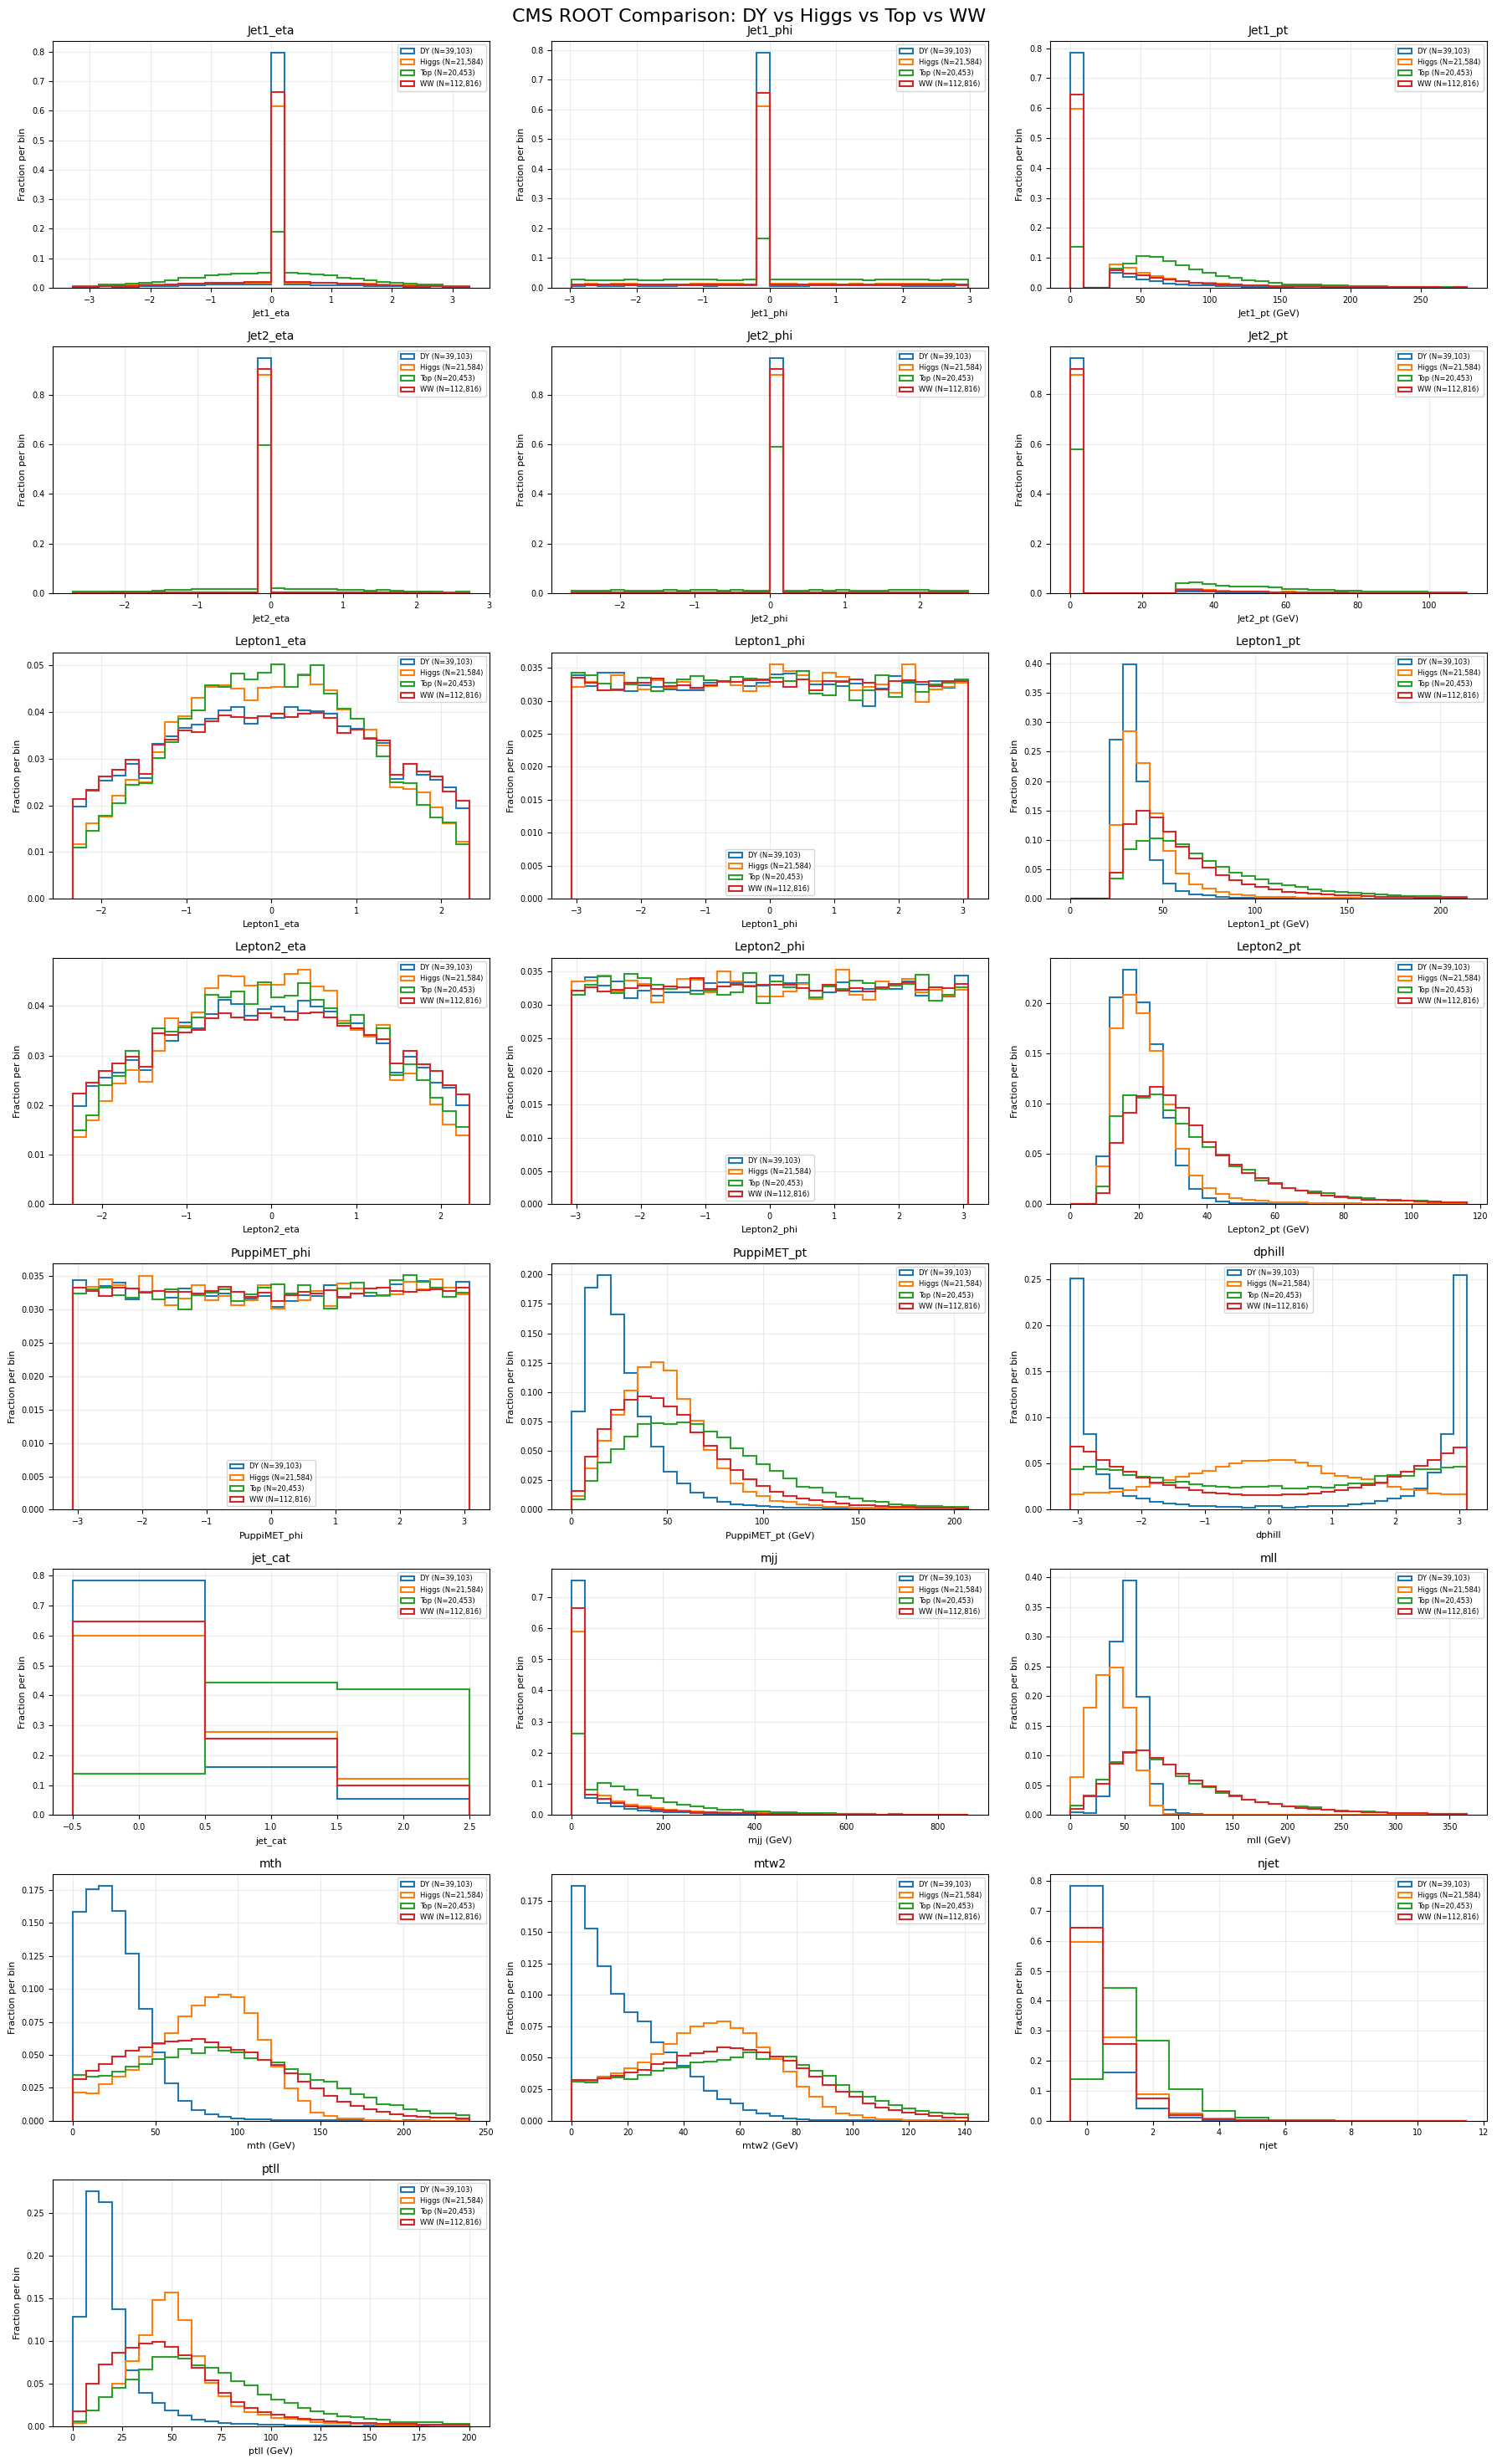


========== COMPLETED ==========
Variables: 22
Combined grid: /content/drive/MyDrive/Dataset_HSF/Comparison_Plots_22_Variables/CMS_22_Variables_Grid.png
PDF: /content/drive/MyDrive/Dataset_HSF/Comparison_Plots_22_Variables/CMS_22_Variables_Comparison.pdf
Individual graph ZIP: /content/drive/MyDrive/Dataset_HSF/Comparison_Plots_22_Variables/CMS_22_Variables_PNGs.zip
Missing branches: []
Empty samples: []
Saved to: /content/drive/MyDrive/Dataset_HSF/Comparison_Plots_22_Variables


In [15]:
import os
import zipfile
import numpy as np
import awkward as ak
import uproot
import matplotlib.pyplot as plt

from contextlib import ExitStack

# =====================================================
# 1. FIND THE DATASET FOLDER
# =====================================================

possible_folders = [
    "/content/drive/MyDrive/Dataset_HSF",
    "/content/drive/MyDrive/Dataset_HS"
]

required_files = [
    "DY-train.root",
    "Higgs.root",
    "Top-train.root",
    "WW-train.root"
]

DATA_DIR = None

for folder in possible_folders:
    if all(
        os.path.isfile(os.path.join(folder, name))
        for name in required_files
    ):
        DATA_DIR = folder
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find all four ROOT files. "
        "Check the Google Drive folder and filenames."
    )

print("Dataset folder:", DATA_DIR)

samples = {
    "DY": os.path.join(DATA_DIR, "DY-train.root"),
    "Higgs": os.path.join(DATA_DIR, "Higgs.root"),
    "Top": os.path.join(DATA_DIR, "Top-train.root"),
    "WW": os.path.join(DATA_DIR, "WW-train.root")
}

# =====================================================
# 2. YOUR NEW 22 VARIABLES
# =====================================================

variables = [
    "Jet1_eta",
    "Jet1_phi",
    "Jet1_pt",
    "Jet2_eta",
    "Jet2_phi",
    "Jet2_pt",
    "Lepton1_eta",
    "Lepton1_phi",
    "Lepton1_pt",
    "Lepton2_eta",
    "Lepton2_phi",
    "Lepton2_pt",
    "PuppiMET_phi",
    "PuppiMET_pt",
    "dphill",
    "jet_cat",
    "mjj",
    "mll",
    "mth",
    "mtw2",
    "njet",
    "ptll"
]

print("Number of variables:", len(variables))

# Variables expected to be non-negative
nonnegative = {
    "Jet1_pt", "Jet2_pt",
    "Lepton1_pt", "Lepton2_pt",
    "PuppiMET_pt",
    "mjj", "mll", "mth", "mtw2",
    "njet", "ptll", "jet_cat"
}

# Integer or category-like variables
discrete = {"jet_cat", "njet"}

# Variables where negative values are meaningful
signed = {
    "Jet1_eta", "Jet1_phi",
    "Jet2_eta", "Jet2_phi",
    "Lepton1_eta", "Lepton1_phi",
    "Lepton2_eta", "Lepton2_phi",
    "PuppiMET_phi", "dphill"
}

# Variables normally expressed in GeV
gev = {
    "Jet1_pt", "Jet2_pt",
    "Lepton1_pt", "Lepton2_pt",
    "PuppiMET_pt",
    "mjj", "mll", "mth", "mtw2", "ptll"
}

# =====================================================
# 3. FIND THE EVENT TREE
# =====================================================

def find_event_tree(root_file):
    for key in root_file.keys():
        obj = root_file[key]

        if hasattr(obj, "num_entries"):
            available = set(obj.keys())

            if any(v in available for v in variables):
                return obj

    raise ValueError(
        "No tree containing the requested variables was found."
    )

# =====================================================
# 4. READ AND CLEAN A VARIABLE
# =====================================================

def read_variable(tree, variable):

    if variable not in tree.keys():
        return None

    # Read the ROOT branch
    arr = tree[variable].array(library="ak")

    # Fill missing values and flatten nested particle arrays.
    # These are complete statements; no parentheses are left open.
    arr = ak.fill_none(arr, np.nan, axis=None)
    arr = ak.flatten(arr, axis=None)

    values = np.asarray(
        ak.to_numpy(arr),
        dtype=float
    ).reshape(-1)

    # Remove missing/non-finite values
    values = values[np.isfinite(values)]

    # Remove extreme negative placeholder values
    values = values[values > -900]

    # Remove negative values only for non-negative quantities
    if variable in nonnegative:
        values = values[values >= 0]

    return values

# =====================================================
# 5. OUTPUT LOCATION
# =====================================================

output_dir = os.path.join(
    DATA_DIR,
    "Comparison_Plots_22_Variables"
)

os.makedirs(output_dir, exist_ok=True)

pdf_path = os.path.join(
    output_dir,
    "CMS_22_Variables_Comparison.pdf"
)

png_path = os.path.join(
    output_dir,
    "CMS_22_Variables_Grid.png"
)

zip_path = os.path.join(
    output_dir,
    "CMS_22_Variables_PNGs.zip"
)

missing_branches = []
empty_samples = []

# =====================================================
# 6. CREATE ALL 22 SUPERIMPOSED GRAPHS
# =====================================================

with ExitStack() as stack:

    root_files = {
        name: stack.enter_context(uproot.open(path))
        for name, path in samples.items()
    }

    trees = {
        name: find_event_tree(root_file)
        for name, root_file in root_files.items()
    }

    # 8 rows x 3 columns = 24 graph spaces
    # Two unused spaces will be removed.
    fig, axes = plt.subplots(
        8, 3,
        figsize=(18, 30)
    )

    axes = axes.flatten()

    for i, variable in enumerate(variables):

        ax = axes[i]
        data = {}

        print(f"Creating graph {i + 1}/22: {variable}")

        # Read the variable from all four samples
        for sample_name, tree in trees.items():

            values = read_variable(tree, variable)

            if values is None:
                missing_branches.append(
                    (sample_name, variable)
                )
                print(
                    f"  Missing: {variable} in {sample_name}"
                )
                continue

            if len(values) == 0:
                empty_samples.append(
                    (sample_name, variable)
                )
                print(
                    f"  No valid values: {sample_name}"
                )

            data[sample_name] = values

        nonempty = [
            values for values in data.values()
            if len(values) > 0
        ]

        if not nonempty:
            ax.set_title(f"{variable}: no valid data")
            ax.text(
                0.5, 0.5,
                "No valid data",
                ha="center",
                va="center",
                transform=ax.transAxes
            )
            continue

        combined = np.concatenate(nonempty)

        # Use shared bins for all samples
        if variable in discrete:

            low = int(np.floor(combined.min()))
            high = int(np.ceil(combined.max()))

            bins = np.arange(
                low - 0.5,
                high + 1.5,
                1
            )

        else:

            if variable in signed:
                low, high = np.percentile(
                    combined, [1, 99]
                )
            else:
                low = 0
                high = np.percentile(combined, 99)

            if not np.isfinite(low):
                low = float(combined.min())

            if not np.isfinite(high) or high <= low:
                high = low + 1.0

            bins = np.linspace(low, high, 31)

        # Superimpose the four datasets
        for sample_name, values in data.items():

            if len(values) == 0:
                continue

            if variable in discrete:
                visible = values
            else:
                visible = values[
                    (values >= bins[0]) &
                    (values <= bins[-1])
                ]

                outside = len(values) - len(visible)

                if outside:
                    print(
                        f"  {sample_name}: {outside} values "
                        "outside the displayed range"
                    )

            if len(visible) == 0:
                continue

            # Each bin shows the fraction of all valid entries.
            weights = np.ones(len(visible)) / len(values)

            ax.hist(
                visible,
                bins=bins,
                weights=weights,
                histtype="step",
                linewidth=1.5,
                label=f"{sample_name} (N={len(values):,})"
            )

        ax.set_title(variable, fontsize=10)

        if variable in gev:
            xlabel = f"{variable} (GeV)"
        else:
            xlabel = variable

        ax.set_xlabel(xlabel, fontsize=8)
        ax.set_ylabel("Fraction per bin", fontsize=8)
        ax.tick_params(axis="both", labelsize=7)
        ax.grid(alpha=0.25)
        ax.legend(fontsize=6, loc="best")

    # Remove the final two unused graph spaces
    fig.delaxes(axes[-1])
    fig.delaxes(axes[-2])

    fig.suptitle(
        "CMS ROOT Comparison: DY vs Higgs vs Top vs WW",
        fontsize=16
    )

    fig.tight_layout(rect=[0, 0, 1, 0.99])

    # Display all graphs directly in Colab
    plt.show()

    # Save a combined image
    fig.savefig(
        png_path,
        dpi=160,
        bbox_inches="tight"
    )

    plt.close(fig)

# =====================================================
# 7. SAVE PDF AND INDIVIDUAL PNG FILES
# =====================================================

# Create a PDF with one graph per page
import matplotlib.backends.backend_pdf as backend_pdf

with backend_pdf.PdfPages(pdf_path) as pdf:

    for variable in variables:

        # Recreate individual graph pages by using the
        # saved combined grid only as the Colab preview.
        # Individual plots are generated below instead.
        with ExitStack() as stack:

            root_files = {
                name: stack.enter_context(uproot.open(path))
                for name, path in samples.items()
            }

            trees = {
                name: find_event_tree(root_file)
                for name, root_file in root_files.items()
            }

            fig_page, ax_page = plt.subplots(figsize=(8, 5))

            data = {}

            for sample_name, tree in trees.items():
                values = read_variable(tree, variable)

                if values is not None and len(values) > 0:
                    data[sample_name] = values

            if data:

                combined = np.concatenate(list(data.values()))

                if variable in discrete:
                    low = int(np.floor(combined.min()))
                    high = int(np.ceil(combined.max()))
                    bins = np.arange(low - 0.5, high + 1.5, 1)
                else:
                    if variable in signed:
                        low, high = np.percentile(combined, [1, 99])
                    else:
                        low = 0
                        high = np.percentile(combined, 99)

                    if not np.isfinite(low):
                        low = float(combined.min())

                    if not np.isfinite(high) or high <= low:
                        high = low + 1.0

                    bins = np.linspace(low, high, 31)

                for sample_name, values in data.items():

                    if variable in discrete:
                        visible = values
                    else:
                        visible = values[
                            (values >= bins[0]) &
                            (values <= bins[-1])
                        ]

                    if len(visible) == 0:
                        continue

                    ax_page.hist(
                        visible,
                        bins=bins,
                        weights=np.ones(len(visible)) / len(values),
                        histtype="step",
                        linewidth=1.6,
                        label=sample_name
                    )

                ax_page.set_title(variable)
                ax_page.set_xlabel(
                    f"{variable} (GeV)"
                    if variable in gev else variable
                )
                ax_page.set_ylabel("Fraction per bin")
                ax_page.grid(alpha=0.25)
                ax_page.legend()

            fig_page.tight_layout()

            pdf.savefig(fig_page)

            individual_png = os.path.join(
                output_dir,
                f"{variables.index(variable) + 1:02d}_{variable}.png"
            )

            fig_page.savefig(
                individual_png,
                dpi=160,
                bbox_inches="tight"
            )

            plt.close(fig_page)

# Bundle all individual PNGs
with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as archive:

    for variable in variables:
        individual_png = os.path.join(
            output_dir,
            f"{variables.index(variable) + 1:02d}_{variable}.png"
        )

        if os.path.exists(individual_png):
            archive.write(
                individual_png,
                arcname=os.path.basename(individual_png)
            )

print("\n========== COMPLETED ==========")
print("Variables:", len(variables))
print("Combined grid:", png_path)
print("PDF:", pdf_path)
print("Individual graph ZIP:", zip_path)
print("Missing branches:", missing_branches)
print("Empty samples:", empty_samples)
print("Saved to:", output_dir)

In [16]:
import os
import numpy as np
import awkward as ak
import uproot
import matplotlib.pyplot as plt

from contextlib import ExitStack

# ==========================================
# 1. FIND YOUR GOOGLE DRIVE DATASET FOLDER
# ==========================================

folders = [
    "/content/drive/MyDrive/Dataset_HSF",
    "/content/drive/MyDrive/Dataset_HS"
]

required_files = [
    "DY-train.root",
    "Higgs.root",
    "Top-train.root",
    "WW-train.root"
]

DATA_DIR = None

for folder in folders:
    if all(
        os.path.isfile(os.path.join(folder, name))
        for name in required_files
    ):
        DATA_DIR = folder
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find all four ROOT files. "
        "Check your Google Drive folder name and filenames."
    )

samples = {
    "DY": os.path.join(DATA_DIR, "DY-train.root"),
    "Higgs": os.path.join(DATA_DIR, "Higgs.root"),
    "Top": os.path.join(DATA_DIR, "Top-train.root"),
    "WW": os.path.join(DATA_DIR, "WW-train.root")
}

print("Dataset folder:", DATA_DIR)

for name, path in samples.items():
    print(name, ":", os.path.basename(path))


# ==========================================
# 2. NEW 22 VARIABLES
# ==========================================

variables = [
    "Jet1_eta",
    "Jet1_phi",
    "Jet1_pt",
    "Jet2_eta",
    "Jet2_phi",
    "Jet2_pt",
    "Lepton1_eta",
    "Lepton1_phi",
    "Lepton1_pt",
    "Lepton2_eta",
    "Lepton2_phi",
    "Lepton2_pt",
    "PuppiMET_phi",
    "PuppiMET_pt",
    "dphill",
    "jet_cat",
    "mjj",
    "mll",
    "mth",
    "mtw2",
    "njet",
    "ptll"
]

print("\nNumber of variables:", len(variables))


# ==========================================
# 3. VARIABLE TYPES
# ==========================================

# Variables expected to be non-negative
nonnegative = {
    "Jet1_pt",
    "Jet2_pt",
    "Lepton1_pt",
    "Lepton2_pt",
    "PuppiMET_pt",
    "mjj",
    "mll",
    "mth",
    "mtw2",
    "njet",
    "jet_cat",
    "ptll"
}

# Discrete or category-like variables
discrete = {
    "jet_cat",
    "njet"
}

# Variables that can have meaningful negative values
signed = {
    "Jet1_eta",
    "Jet1_phi",
    "Jet2_eta",
    "Jet2_phi",
    "Lepton1_eta",
    "Lepton1_phi",
    "Lepton2_eta",
    "Lepton2_phi",
    "PuppiMET_phi",
    "dphill"
}

# Variables measured in GeV
gev = {
    "Jet1_pt",
    "Jet2_pt",
    "Lepton1_pt",
    "Lepton2_pt",
    "PuppiMET_pt",
    "mjj",
    "mll",
    "mth",
    "mtw2",
    "ptll"
}


# ==========================================
# 4. FIND THE EVENT TREE
# ==========================================

def find_tree(root_file):
    for key in root_file.keys():
        obj = root_file[key]

        if hasattr(obj, "num_entries"):
            available = set(obj.keys())

            if any(v in available for v in variables):
                return obj

    raise ValueError(
        "No suitable event tree found in ROOT file."
    )


# ==========================================
# 5. READ AND CLEAN A VARIABLE
# ==========================================

def read_variable(tree, variable):

    if variable not in tree.keys():
        return None

    # Read branch using Awkward Array
    arr = tree[variable].array(library="ak")

    # Flatten nested particle collections
    arr = ak.flatten(arr, axis=None)

    # Replace missing values with NaN
    arr = ak.fill_none(arr, np.nan, axis=None)

    values = np.asarray(
        ak.to_numpy(arr),
        dtype=float
    ).reshape(-1)

    # Remove NaN and infinite values
    values = values[np.isfinite(values)]

    # Remove extreme negative placeholders such as -

Dataset folder: /content/drive/MyDrive/Dataset_HSF
DY : DY-train.root
Higgs : Higgs.root
Top : Top-train.root
WW : WW-train.root

Number of variables: 22


In [17]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
!pip -q install uproot awkward scikit-learn joblib

In [19]:
import os
import json
import numpy as np
import pandas as pd
import awkward as ak
import uproot
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)
import joblib
import matplotlib.pyplot as plt

# ============================================
# 1. FIND YOUR ROOT FILES
# ============================================

folders = [
    "/content/drive/MyDrive/Dataset_HSF",
    "/content/drive/MyDrive/Dataset_HS"
]

required_files = [
    "DY-train.root",
    "Higgs.root",
    "Top-train.root",
    "WW-train.root"
]

DATA_DIR = None

for folder in folders:
    if all(os.path.isfile(os.path.join(folder, f))
           for f in required_files):
        DATA_DIR = folder
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find all four ROOT files. "
        "Check your Google Drive folder and filenames."
    )

samples = {
    "DY": os.path.join(DATA_DIR, "DY-train.root"),
    "Higgs": os.path.join(DATA_DIR, "Higgs.root"),
    "Top": os.path.join(DATA_DIR, "Top-train.root"),
    "WW": os.path.join(DATA_DIR, "WW-train.root")
}

# ============================================
# 2. SELECTED FEATURES
# ============================================

FEATURES = [
    "mth",
    "mtw2",
    "ptll",
    "PuppiMET_pt",
    "mll",
    "Lepton1_pt",
    "njet",
    "jet_cat"
]

# These quantities should be non-negative.
NONNEGATIVE_FEATURES = [
    "mth",
    "mtw2",
    "ptll",
    "PuppiMET_pt",
    "mll",
    "Lepton1_pt",
    "njet",
    "jet_cat"
]

# ============================================
# 3. FIND THE EVENT TREE
# ============================================

def find_tree(root_file):
    for key in root_file.keys():
        obj = root_file[key]

        if hasattr(obj, "num_entries"):
            available = set(obj.keys())

            if set(FEATURES).issubset(available):
                return obj

    raise ValueError(
        "Could not find a ROOT tree containing all "
        f"selected features: {FEATURES}"
    )

# ============================================
# 4. READ EACH DATASET
# ============================================

frames = []

for sample_name, path in samples.items():

    print(f"\nReading {sample_name}: {os.path.basename(path)}")

    with uproot.open(path) as root_file:

        tree = find_tree(root_file)
        columns = {}

        for feature in FEATURES:
            arr = tree[feature].array(library="ak")
            arr = ak.fill_none(arr, np.nan)

            try:
                values = np.asarray(
                    ak.to_numpy(arr),
                    dtype=np.float64
                )
            except Exception as exc:
                raise ValueError(
                    f"{feature} is not a simple scalar-per-event "
                    "branch. It needs separate handling."
                ) from exc

            if values.ndim != 1:
                raise ValueError(
                    f"{feature} is not one value per event."
                )

            columns[feature] = values

        df = pd.DataFrame(columns)

    original_count = len(df)

    # Remove infinite values and extreme negative placeholders.
    df[FEATURES] = df[FEATURES].replace(
        [np.inf, -np.inf], np.nan
    )
    df[FEATURES] = df[FEATURES].mask(
        df[FEATURES] < -900
    )

    # Reject negative values for these non-negative quantities.
    for feature in NONNEGATIVE_FEATURES:
        df.loc[df[feature] < 0, feature] = np.nan

    # Keep only events with all eight valid features.
    df = df.dropna(subset=FEATURES).copy()

    # Higgs = 1; all three backgrounds = 0.
    df["label"] = 1 if sample_name == "Higgs" else 0

    print("Original events:", original_count)
    print("Usable events:", len(df))
    print("Removed events:", original_count - len(df))

    frames.append(df)

# Combine all four datasets.
all_data = pd.concat(frames, ignore_index=True)

X = all_data[FEATURES].to_numpy(dtype=np.float32)
y = all_data["label"].to_numpy(dtype=np.int32)

print("\nCombined dataset shape:", X.shape)
print("Background events:", int(np.sum(y == 0)))
print("Higgs events:", int(np.sum(y == 1)))

print("\nLabels:")
print("0 = DY + Top + WW background")
print("1 = Higgs signal")


Reading DY: DY-train.root
Original events: 39103
Usable events: 39103
Removed events: 0

Reading Higgs: Higgs.root
Original events: 21584
Usable events: 21584
Removed events: 0

Reading Top: Top-train.root
Original events: 20453
Usable events: 20453
Removed events: 0

Reading WW: WW-train.root
Original events: 112816
Usable events: 112816
Removed events: 0

Combined dataset shape: (193956, 8)
Background events: 172372
Higgs events: 21584

Labels:
0 = DY + Top + WW background
1 = Higgs signal


In [20]:
# 20% reserved for the final test.
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Use 15% of the remaining training data for validation.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.15,
    random_state=42,
    stratify=y_train_full
)

# Fit the scaler only on the training data.
scaler = RobustScaler()

X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

print("Training events:", len(y_train))
print("Validation events:", len(y_val))
print("Testing events:", len(y_test))

# Calculate weights to account for class imbalance.
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(c): float(w)
    for c, w in zip(classes, weights)
}

print("\nClass weights:", class_weights)

Training events: 131889
Validation events: 23275
Testing events: 38792

Class weights: {0: 0.5626087772583012, 1: 4.493050350889146}


In [21]:
tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(len(FEATURES),)),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.20),

    tf.keras.layers.Dense(16, activation="relu"),

    # One output score: Higgs signal versus background.
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,585 (14.00 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 192 (768.00 B)

In [22]:
output_dir = os.path.join(
    DATA_DIR,
    "Neural_Network_OptionA"
)
os.makedirs(output_dir, exist_ok=True)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=8,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=50,
    batch_size=1024,
    class_weight=class_weights,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 21s 57ms/step - accuracy: 0.7199 - auc: 0.8500 - loss: 0.4783 - precision: 0.2629 - recall: 0.8407 - val_accuracy: 0.8734 - val_auc: 0.8792 - val_loss: 0.3386 - val_precision: 0.4468 - val_recall: 0.5768 - learning_rate: 0.0010
Epoch 2/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.7753 - auc: 0.8850 - loss: 0.4117 - precision: 0.3143 - recall: 0.8627 - val_accuracy: 0.8218 - val_auc: 0.8924 - val_loss: 0.3490 - val_precision: 0.3642 - val_recall: 0.8069 - learning_rate: 0.0010
Epoch 3/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - accuracy: 0.7808 - auc: 0.8895 - loss: 0.4034 - precision: 0.3209 - recall: 0.8692 - val_accuracy: 0.7989 - val_auc: 0.8966 - val_loss: 0.3817 - val_precision: 0.3408 - val_recall: 0.8641 - learning_rate: 0.0010
Epoch 4/50
129/129 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.7828 - auc: 0.8915 - loss: 0.3987 - precision: 0.3235 - recall: 0.8716 - val_accuracy: 0.8019 - val_auc: 0.8989 - val_loss: 0.3831 

In [23]:
# Predict the Higgs signal score for each test event.
y_score = model.predict(
    X_test_scaled,
    verbose=0
).ravel()

# Use 0.5 as the initial classification threshold.
y_pred = (y_score >= 0.5).astype(int)

test_auc = roc_auc_score(y_test, y_score)

print(f"Test ROC-AUC: {test_auc:.4f}")
print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Background", "Higgs signal"],
        digits=4,
        zero_division=0
    )
)

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Test ROC-AUC: 0.9045

Classification report:
              precision    recall  f1-score   support

  Background     0.9825    0.7858    0.8732     34475
Higgs signal     0.3417    0.8881    0.4936      4317

    accuracy                         0.7972     38792
   macro avg     0.6621    0.8370    0.6834     38792
weighted avg     0.9112    0.7972    0.8309     38792

Confusion matrix:
[[27090  7385]
 [  483  3834]]


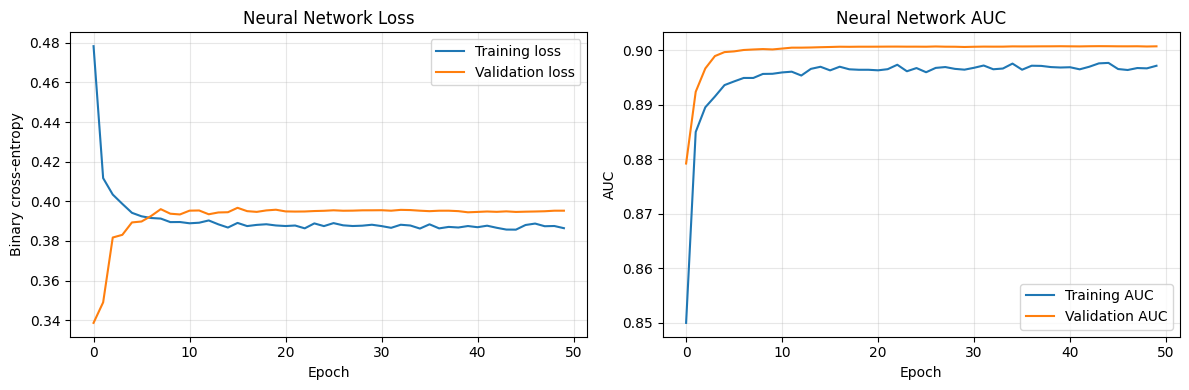

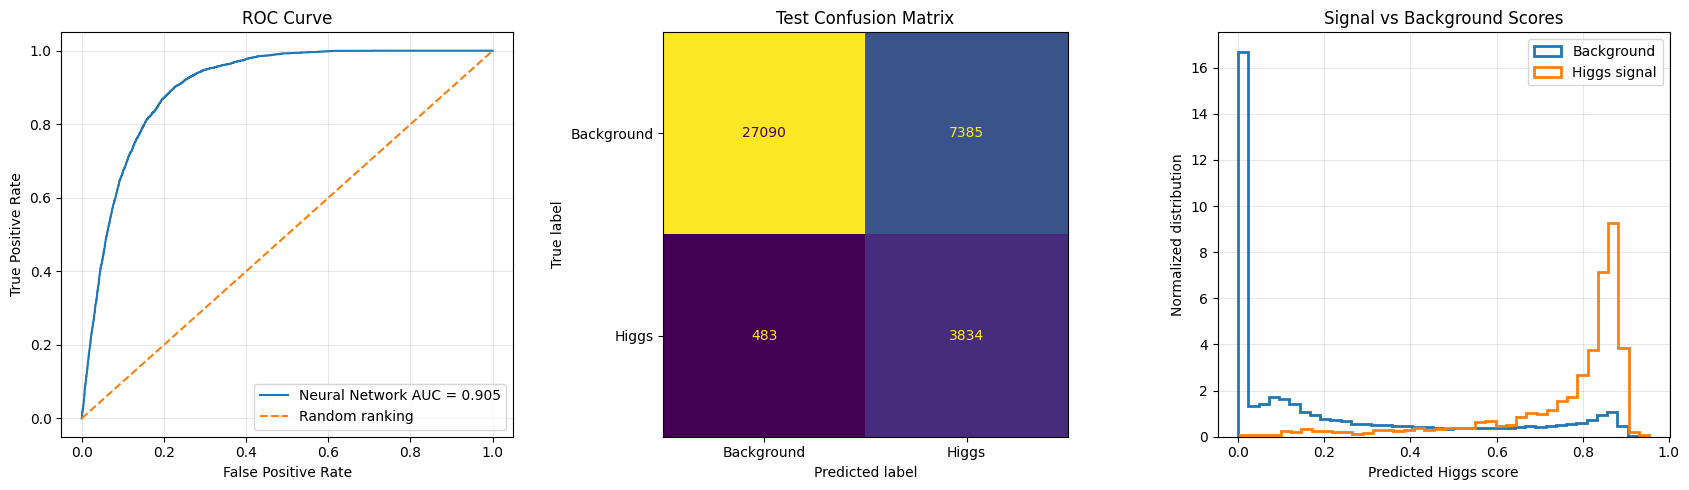

In [24]:
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

# ============================================
# Plot 1: Training and validation history
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("Neural Network Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history["auc"], label="Training AUC")
axes[1].plot(history.history["val_auc"], label="Validation AUC")
axes[1].set_title("Neural Network AUC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("AUC")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

history_plot_path = os.path.join(
    output_dir, "training_history.png"
)
plt.savefig(history_plot_path, dpi=160, bbox_inches="tight")
plt.show()

# ============================================
# Plot 2: ROC curve, confusion matrix and scores
# ============================================

fpr, tpr, thresholds = roc_curve(y_test, y_score)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# ROC curve
axes[0].plot(fpr, tpr, label=f"Neural Network AUC = {test_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "--", label="Random ranking")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Background", "Higgs"]
)
display.plot(ax=axes[1], colorbar=False, values_format="d")
axes[1].set_title("Test Confusion Matrix")

# Predicted score distribution
axes[2].hist(
    y_score[y_test == 0],
    bins=40,
    density=True,
    histtype="step",
    linewidth=2,
    label="Background"
)
axes[2].hist(
    y_score[y_test == 1],
    bins=40,
    density=True,
    histtype="step",
    linewidth=2,
    label="Higgs signal"
)
axes[2].set_xlabel("Predicted Higgs score")
axes[2].set_ylabel("Normalized distribution")
axes[2].set_title("Signal vs Background Scores")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()

evaluation_plot_path = os.path.join(
    output_dir, "test_evaluation.png"
)
plt.savefig(evaluation_plot_path, dpi=160, bbox_inches="tight")
plt.show()

In [25]:
import joblib
import json

model_path = os.path.join(
    output_dir, "higgs_vs_background_nn.keras"
)

scaler_path = os.path.join(
    output_dir, "robust_scaler.joblib"
)

features_path = os.path.join(
    output_dir, "selected_features.json"
)

model.save(model_path)
joblib.dump(scaler, scaler_path)

with open(features_path, "w") as f:
    json.dump(FEATURES, f, indent=4)

print("Model saved:", model_path)
print("Scaler saved:", scaler_path)
print("Feature list saved:", features_path)
print("Plots saved in:", output_dir)

Model saved: /content/drive/MyDrive/Dataset_HSF/Neural_Network_OptionA/higgs_vs_background_nn.keras
Scaler saved: /content/drive/MyDrive/Dataset_HSF/Neural_Network_OptionA/robust_scaler.joblib
Feature list saved: /content/drive/MyDrive/Dataset_HSF/Neural_Network_OptionA/selected_features.json
Plots saved in: /content/drive/MyDrive/Dataset_HSF/Neural_Network_OptionA


In [26]:

import numpy as np
from sklearn.metrics import (
    precision_recall_curve,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# 1. Predict scores on the validation set
val_scores = model.predict(
    X_val_scaled,
    verbose=0
).ravel()

# 2. Calculate precision and recall at different thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_scores
)

# 3. Find the threshold with the highest validation F1-score
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("Best threshold on validation set:", best_threshold)
print("Validation precision:", precision[best_index])
print("Validation recall:", recall[best_index])
print("Validation F1-score:", f1_scores[best_index])

# 4. Apply this threshold to the untouched test set
test_scores = model.predict(
    X_test_scaled,
    verbose=0
).ravel()

test_predictions = (
    test_scores >= best_threshold
).astype(int)

print("\nTest ROC-AUC:", roc_auc_score(y_test, test_scores))

print("\nTest classification report at tuned threshold:")
print(
    classification_report(
        y_test,
        test_predictions,
        labels=[0, 1],
        target_names=["Background", "Higgs signal"],
        digits=4,
        zero_division=0
    )
)

print("Test confusion matrix:")
print(
    confusion_matrix(
        y_test,
        test_predictions,
        labels=[0, 1]
    )
)


Best threshold on validation set: 0.764501
Validation precision: 0.4437356468486859
Validation recall: 0.6714285714285714
Validation F1-score: 0.5343370716988965

Test ROC-AUC: 0.9045481958017807

Test classification report at tuned threshold:
              precision    recall  f1-score   support

  Background     0.9574    0.8961    0.9257     34475
Higgs signal     0.4510    0.6815    0.5428      4317

    accuracy                         0.8722     38792
   macro avg     0.7042    0.7888    0.7342     38792
weighted avg     0.9010    0.8722    0.8831     38792

Test confusion matrix:
[[30893  3582]
 [ 1375  2942]]


Final classification threshold: 0.7645009756088257

========== FINAL TEST RESULTS ==========
ROC-AUC: 0.9045
Average precision (PR-AUC summary): 0.4748
Accuracy: 0.8722
Higgs precision: 0.4510
Higgs recall: 0.6815
Higgs F1-score: 0.5428

Classification report:
              precision    recall  f1-score   support

  Background     0.9574    0.8961    0.9257     34475
Higgs signal     0.4510    0.6815    0.5428      4317

    accuracy                         0.8722     38792
   macro avg     0.7042    0.7888    0.7342     38792
weighted avg     0.9010    0.8722    0.8831     38792

Confusion matrix:
[[30893  3582]
 [ 1375  2942]]


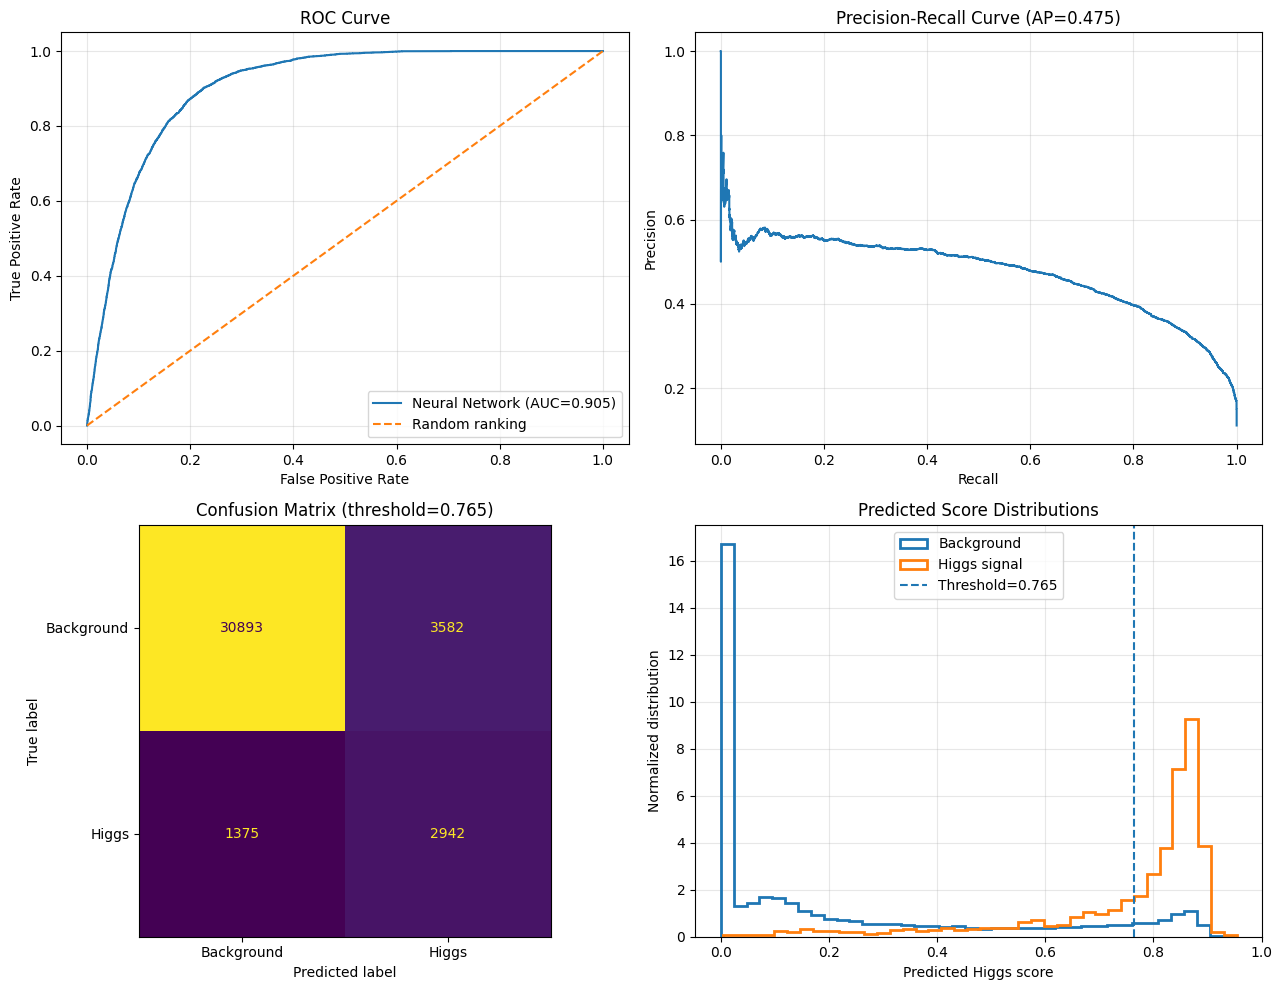


Saved evaluation plot: /content/drive/MyDrive/Dataset_HSF/Neural_Network_OptionA/final_model_evaluation.png
Saved test metrics: /content/drive/MyDrive/Dataset_HSF/Neural_Network_OptionA/final_test_metrics.json
Output folder: /content/drive/MyDrive/Dataset_HSF/Neural_Network_OptionA


In [27]:

import os
import json
import joblib
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

# ==========================================
# 1. SET OUTPUT FOLDER AND THRESHOLD
# ==========================================

output_dir = os.path.join(
    DATA_DIR,
    "Neural_Network_OptionA"
)
os.makedirs(output_dir, exist_ok=True)

threshold_path = os.path.join(
    output_dir,
    "classification_threshold.json"
)

# Use the validation-selected threshold.
# Read the saved threshold if available.
if os.path.exists(threshold_path):
    with open(threshold_path, "r") as f:
        threshold = float(json.load(f)["threshold"])
elif "best_threshold" in globals():
    threshold = float(best_threshold)
else:
    raise ValueError(
        "Threshold not found. Run the validation threshold-tuning cell first."
    )

print("Final classification threshold:", threshold)

# ==========================================
# 2. PREDICT ON THE TEST SET
# ==========================================

test_scores = model.predict(
    X_test_scaled,
    verbose=0
).ravel()

test_predictions = (
    test_scores >= threshold
).astype(int)

# ==========================================
# 3. CALCULATE FINAL METRICS
# ==========================================

test_auc = roc_auc_score(y_test, test_scores)
test_ap = average_precision_score(y_test, test_scores)
test_accuracy = accuracy_score(y_test, test_predictions)

report = classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Background", "Higgs signal"],
    output_dict=True,
    zero_division=0
)

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"ROC-AUC: {test_auc:.4f}")
print(f"Average precision (PR-AUC summary): {test_ap:.4f}")
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Higgs precision: {report['Higgs signal']['precision']:.4f}")
print(f"Higgs recall: {report['Higgs signal']['recall']:.4f}")
print(f"Higgs F1-score: {report['Higgs signal']['f1-score']:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Background", "Higgs signal"],
    digits=4,
    zero_division=0
))

print("Confusion matrix:")
print(cm)

# ==========================================
# 4. CREATE FOUR FINAL EVALUATION PLOTS
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# ROC curve
fpr, tpr, _ = roc_curve(y_test, test_scores)

axes[0, 0].plot(
    fpr, tpr,
    label=f"Neural Network (AUC={test_auc:.3f})"
)
axes[0, 0].plot([0, 1], [0, 1], "--", label="Random ranking")
axes[0, 0].set_title("ROC Curve")
axes[0, 0].set_xlabel("False Positive Rate")
axes[0, 0].set_ylabel("True Positive Rate")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Precision-recall curve
precision, recall, _ = precision_recall_curve(
    y_test, test_scores
)

axes[0, 1].plot(recall, precision)
axes[0, 1].set_title(
    f"Precision-Recall Curve (AP={test_ap:.3f})"
)
axes[0, 1].set_xlabel("Recall")
axes[0, 1].set_ylabel("Precision")
axes[0, 1].grid(alpha=0.3)

# Confusion matrix at the tuned threshold
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Background", "Higgs"]
)
display.plot(
    ax=axes[1, 0],
    colorbar=False,
    values_format="d"
)
axes[1, 0].set_title(
    f"Confusion Matrix (threshold={threshold:.3f})"
)

# Predicted score distributions
axes[1, 1].hist(
    test_scores[y_test == 0],
    bins=40,
    density=True,
    histtype="step",
    linewidth=2,
    label="Background"
)
axes[1, 1].hist(
    test_scores[y_test == 1],
    bins=40,
    density=True,
    histtype="step",
    linewidth=2,
    label="Higgs signal"
)
axes[1, 1].axvline(
    threshold,
    linestyle="--",
    label=f"Threshold={threshold:.3f}"
)
axes[1, 1].set_title("Predicted Score Distributions")
axes[1, 1].set_xlabel("Predicted Higgs score")
axes[1, 1].set_ylabel("Normalized distribution")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()

plot_path = os.path.join(
    output_dir,
    "final_model_evaluation.png"
)

plt.savefig(
    plot_path,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 5. SAVE THE FINAL METRICS
# ==========================================

metrics_path = os.path.join(
    output_dir,
    "final_test_metrics.json"
)

results = {
    "model": "Feedforward Neural Network (MLP)",
    "task": "Higgs signal vs background",
    "features": FEATURES,
    "threshold": threshold,
    "threshold_selection": "Maximum validation F1-score",
    "test_roc_auc": float(test_auc),
    "test_average_precision": float(test_ap),
    "test_accuracy": float(test_accuracy),
    "classification_report": report,
    "confusion_matrix": cm.tolist()
}

with open(metrics_path, "w") as f:
    json.dump(results, f, indent=4)

print("\nSaved evaluation plot:", plot_path)
print("Saved test metrics:", metrics_path)
print("Output folder:", output_dir)


In [28]:

import os
import json
import joblib

os.makedirs(output_dir, exist_ok=True)

# Save the trained neural network
model.save(
    os.path.join(output_dir, "higgs_vs_background_nn.keras")
)

# Save the feature scaler
joblib.dump(
    scaler,
    os.path.join(output_dir, "robust_scaler.joblib")
)

# Save the ordered list of inputs
with open(
    os.path.join(output_dir, "selected_features.json"),
    "w"
) as f:
    json.dump(FEATURES, f, indent=4)

# Save the threshold used for classification
with open(
    os.path.join(output_dir, "classification_threshold.json"),
    "w"
) as f:
    json.dump(
        {
            "threshold": threshold,
            "selection_method": "Maximum validation F1-score"
        },
        f,
        indent=4
    )

print("Complete model package saved successfully!")
print("Location:", output_dir)


Complete model package saved successfully!
Location: /content/drive/MyDrive/Dataset_HSF/Neural_Network_OptionA


In [29]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loaded model: /content/drive/MyDrive/Dataset_HSF/Neural_Network_OptionA/higgs_vs_background_nn.keras
Features: ['mth', 'mtw2', 'ptll', 'PuppiMET_pt', 'mll', 'Lepton1_pt', 'njet', 'jet_cat']
Classification threshold: 0.7645009756088257

Test folder: /content/drive/MyDrive/Dataset_HSF
DY -> /content/drive/MyDrive/Dataset_HSF/DY-test.root
Higgs -> /content/drive/MyDrive/Dataset_HSF/Higgs-test.root
Top -> /content/drive/MyDrive/Dataset_HSF/Top-test.root
WW -> /content/drive/MyDrive/Dataset_HSF/WW-test.root
DY: 90,090 original events, 90,089 usable events
Higgs: 136,662 original events, 136,662 usable events
Top: 23,902 original events, 23,902 usable events
WW: 200,890 original events, 200,890 usable events

External test dataset shape: (451543, 8)
Higgs events: 136662
Background events: 314881

INDEPENDENT TEST DATASET RESULTS
ROC-AUC: 0.8823
Average precision: 0.7076
Accuracy: 0.8120
Threshold: 0.764501

Classification report:
              precision    recall  f1-score   support

  Backg

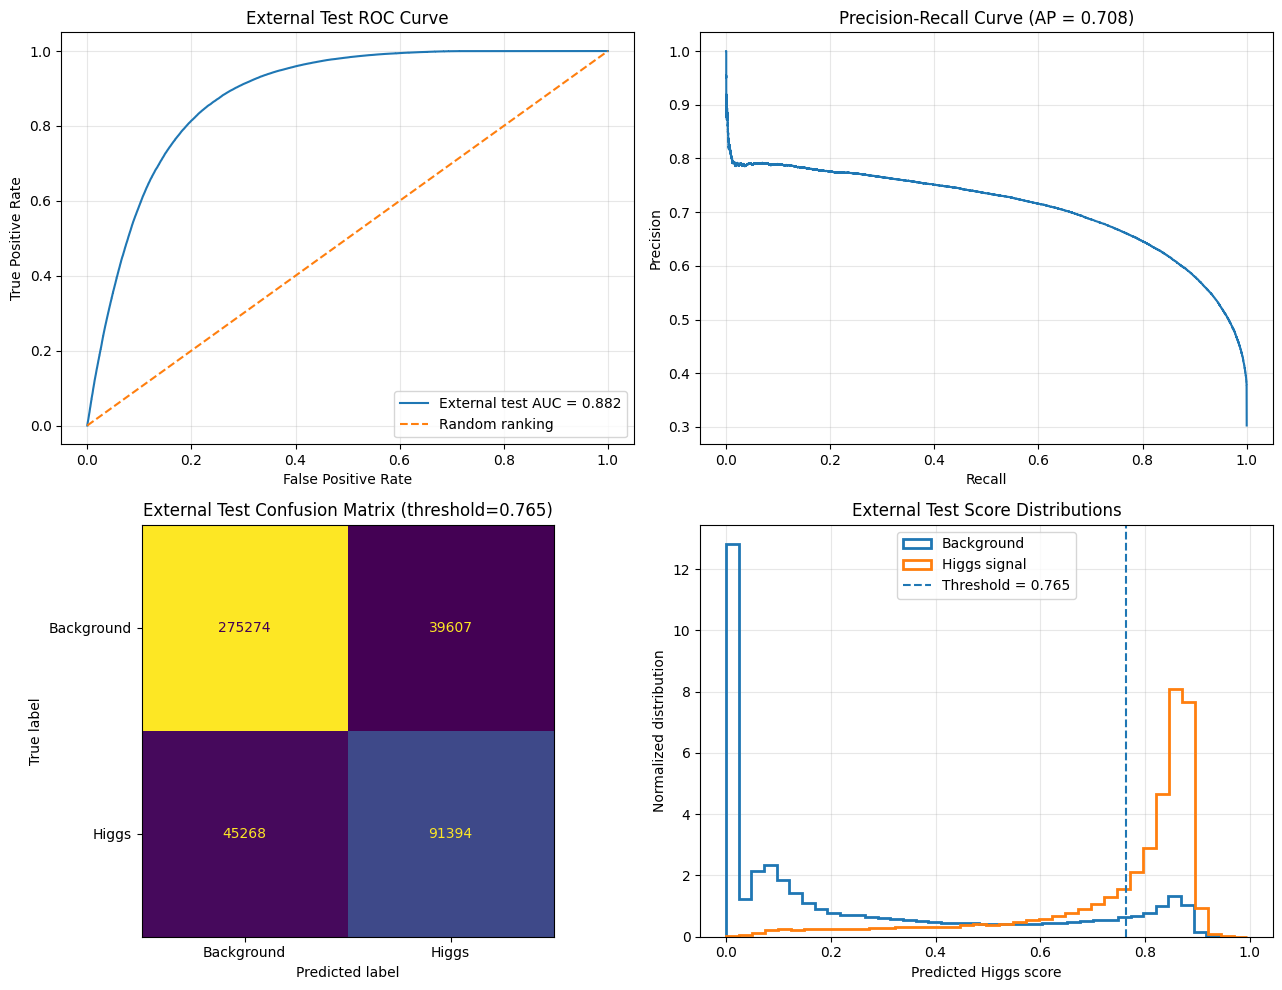


Results saved to:
/content/drive/MyDrive/Dataset_HSF/Neural_Network_OptionA/Independent_Test_Results
Predictions: /content/drive/MyDrive/Dataset_HSF/Neural_Network_OptionA/Independent_Test_Results/independent_test_predictions.csv
Metrics: /content/drive/MyDrive/Dataset_HSF/Neural_Network_OptionA/Independent_Test_Results/independent_test_metrics.json


In [32]:

import os
import json
import glob
import joblib
import numpy as np
import pandas as pd
import awkward as ak
import uproot
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

# ====================================================
# 1. LOCATE THE SAVED MODEL
# ====================================================

candidate_model_dirs = [
    "/content/drive/MyDrive/Dataset_HSF/Neural_Network_OptionA",
    "/content/drive/MyDrive/Dataset_HS/Neural_Network_OptionA"
]

MODEL_DIR = None

for folder in candidate_model_dirs:
    if (
        os.path.isfile(os.path.join(folder, "higgs_vs_background_nn.keras"))
        and os.path.isfile(os.path.join(folder, "robust_scaler.joblib"))
    ):
        MODEL_DIR = folder
        break

if MODEL_DIR is None:
    raise FileNotFoundError(
        "Trained model or scaler not found. "
        "Make sure you saved both files in "
        "Neural_Network_OptionA in Google Drive."
    )

model_path = os.path.join(
    MODEL_DIR, "higgs_vs_background_nn.keras"
)
scaler_path = os.path.join(
    MODEL_DIR, "robust_scaler.joblib"
)
features_path = os.path.join(
    MODEL_DIR, "selected_features.json"
)
threshold_path = os.path.join(
    MODEL_DIR, "classification_threshold.json"
)

model = tf.keras.models.load_model(model_path)
scaler = joblib.load(scaler_path)

if os.path.isfile(features_path):
    with open(features_path, "r") as f:
        FEATURES = json.load(f)
else:
    FEATURES = [
        "mth", "mtw2", "ptll", "PuppiMET_pt",
        "mll", "Lepton1_pt", "njet", "jet_cat"
    ]

# Use the validation-selected threshold.
# If no threshold file exists, use the previously reported
# validation-selected threshold.
if os.path.isfile(threshold_path):
    with open(threshold_path, "r") as f:
        THRESHOLD = float(json.load(f)["threshold"])
else:
    THRESHOLD = 0.764501
    print("Warning: threshold file not found; using 0.764501.")

print("Loaded model:", model_path)
print("Features:", FEATURES)
print("Classification threshold:", THRESHOLD)


# ====================================================
# 2. FIND THE FOUR NEW TEST FILES
# ====================================================

TEST_FILENAMES = {
    "DY": "DY-test.root",
    "Higgs": "Higgs-test.root",
    "Top": "Top-test.root",
    "WW": "WW-test.root"
}

MYDRIVE = "/content/drive/MyDrive"

# First check common folders.
candidate_test_dirs = [
    "/content/drive/MyDrive/Dataset_HSF",
    "/content/drive/MyDrive/Dataset_HS",
    "/content/drive/MyDrive/Test_Data",
    "/content/drive/MyDrive/Dataset_HSF/Test_Data",
    "/content/drive/MyDrive/Dataset_HS/Test_Data"
]

TEST_DIR = None

for folder in candidate_test_dirs:
    if all(
        os.path.isfile(os.path.join(folder, filename))
        for filename in TEST_FILENAMES.values()
    ):
        TEST_DIR = folder
        break

# If necessary, search other folders in Drive.
if TEST_DIR is None:
    matching_dirs = []

    for current_dir, subdirs, filenames in os.walk(MYDRIVE):
        if set(TEST_FILENAMES.values()).issubset(set(filenames)):
            matching_dirs.append(current_dir)

    if len(matching_dirs) == 1:
        TEST_DIR = matching_dirs[0]
    elif len(matching_dirs) > 1:
        raise RuntimeError(
            "The four test files appear together in multiple folders:\n"
            + "\n".join(matching_dirs)
            + "\nSet TEST_DIR manually to the correct folder."
        )

if TEST_DIR is None:
    raise FileNotFoundError(
        "Could not find all four test files in Google Drive. "
        "Place them together in a folder and set TEST_DIR manually."
    )

test_files = {
    name: os.path.join(TEST_DIR, filename)
    for name, filename in TEST_FILENAMES.items()
}

print("\nTest folder:", TEST_DIR)

for name, path in test_files.items():
    print(name, "->", path)


# ====================================================
# 3. READ THE SAME EIGHT FEATURES
# ====================================================

NONNEGATIVE_FEATURES = {
    "mth", "mtw2", "ptll", "PuppiMET_pt",
    "mll", "Lepton1_pt", "njet", "jet_cat"
}

def find_event_tree(root_file):
    for key in root_file.keys():
        obj = root_file[key]

        if hasattr(obj, "num_entries"):
            if set(FEATURES).issubset(set(obj.keys())):
                return obj

    raise ValueError(
        f"No event tree containing all required features: {FEATURES}"
    )


def read_test_sample(path, sample_name):
    with uproot.open(path) as root_file:
        tree = find_event_tree(root_file)

        columns = {}

        for feature in FEATURES:
            arr = tree[feature].array(library="ak")
            arr = ak.fill_none(arr, np.nan)

            try:
                values = np.asarray(
                    ak.to_numpy(arr),
                    dtype=np.float64
                )
            except Exception as exc:
                raise ValueError(
                    f"{feature} is not a scalar-per-event branch "
                    f"in {path}"
                ) from exc

            if values.ndim != 1:
                raise ValueError(
                    f"{feature} must contain one value per event: {path}"
                )

            columns[feature] = values

        df = pd.DataFrame(columns)

    original_count = len(df)

    # Apply the same data cleaning used for training.
    df[FEATURES] = df[FEATURES].replace(
        [np.inf, -np.inf], np.nan
    )

    df[FEATURES] = df[FEATURES].mask(
        df[FEATURES] < -900
    )

    for feature in NONNEGATIVE_FEATURES.intersection(FEATURES):
        df.loc[df[feature] < 0, feature] = np.nan

    # Use only events with all required features.
    df = df.dropna(subset=FEATURES).copy()

    # Ground-truth labels come from the sample identity.
    df["label"] = 1 if sample_name == "Higgs" else 0
    df["source"] = sample_name

    print(
        f"{sample_name}: {original_count:,} original events, "
        f"{len(df):,} usable events"
    )

    return df


# ====================================================
# 4. BUILD THE INDEPENDENT TEST DATASET
# ====================================================

test_frames = []

for sample_name, path in test_files.items():
    test_frames.append(
        read_test_sample(path, sample_name)
    )

test_data = pd.concat(
    test_frames,
    ignore_index=True
)

if test_data.empty:
    raise ValueError("No usable test events were found.")

X_external = test_data[FEATURES].to_numpy(dtype=np.float32)
y_external = test_data["label"].to_numpy(dtype=np.int32)

print("\nExternal test dataset shape:", X_external.shape)
print("Higgs events:", int(np.sum(y_external == 1)))
print("Background events:", int(np.sum(y_external == 0)))


# ====================================================
# 5. APPLY THE TRAINING SCALER AND PREDICT
# ====================================================

# Do NOT fit a new scaler on the test data.
X_external_scaled = scaler.transform(X_external).astype(np.float32)

higgs_scores = model.predict(
    X_external_scaled,
    verbose=0
).ravel()

predictions = (
    higgs_scores >= THRESHOLD
).astype(int)


# ====================================================
# 6. EVALUATE THE INDEPENDENT TEST DATASET
# ====================================================

if len(np.unique(y_external)) < 2:
    raise ValueError(
        "Both Higgs and background samples are required "
        "to calculate ROC-AUC."
    )

external_auc = roc_auc_score(y_external, higgs_scores)
external_ap = average_precision_score(y_external, higgs_scores)
external_accuracy = accuracy_score(y_external, predictions)

print("\n" + "=" * 55)
print("INDEPENDENT TEST DATASET RESULTS")
print("=" * 55)

print(f"ROC-AUC: {external_auc:.4f}")
print(f"Average precision: {external_ap:.4f}")
print(f"Accuracy: {external_accuracy:.4f}")
print(f"Threshold: {THRESHOLD:.6f}")

print("\nClassification report:")

print(classification_report(
    y_external,
    predictions,
    labels=[0, 1],
    target_names=["Background", "Higgs signal"],
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    y_external,
    predictions,
    labels=[0, 1]
)

print("Confusion matrix:")
print(cm)


# ====================================================
# 7. PLOT EXTERNAL TEST RESULTS
# ====================================================

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# ROC curve
fpr, tpr, _ = roc_curve(y_external, higgs_scores)

axes[0, 0].plot(
    fpr, tpr,
    label=f"External test AUC = {external_auc:.3f}"
)
axes[0, 0].plot([0, 1], [0, 1], "--", label="Random ranking")
axes[0, 0].set_title("External Test ROC Curve")
axes[0, 0].set_xlabel("False Positive Rate")
axes[0, 0].set_ylabel("True Positive Rate")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Precision-recall curve
precision, recall, _ = precision_recall_curve(
    y_external,
    higgs_scores
)

axes[0, 1].plot(recall, precision)
axes[0, 1].set_title(
    f"Precision-Recall Curve (AP = {external_ap:.3f})"
)
axes[0, 1].set_xlabel("Recall")
axes[0, 1].set_ylabel("Precision")
axes[0, 1].grid(alpha=0.3)

# Confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Background", "Higgs"]
)
display.plot(
    ax=axes[1, 0],
    colorbar=False,
    values_format="d"
)
axes[1, 0].set_title(
    f"External Test Confusion Matrix (threshold={THRESHOLD:.3f})"
)

# Predicted scores
axes[1, 1].hist(
    higgs_scores[y_external == 0],
    bins=40,
    density=True,
    histtype="step",
    linewidth=2,
    label="Background"
)
axes[1, 1].hist(
    higgs_scores[y_external == 1],
    bins=40,
    density=True,
    histtype="step",
    linewidth=2,
    label="Higgs signal"
)
axes[1, 1].axvline(
    THRESHOLD,
    linestyle="--",
    label=f"Threshold = {THRESHOLD:.3f}"
)
axes[1, 1].set_title("External Test Score Distributions")
axes[1, 1].set_xlabel("Predicted Higgs score")
axes[1, 1].set_ylabel("Normalized distribution")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ====================================================
# 8. SAVE THE EXTERNAL TEST PREDICTIONS AND METRICS
# ====================================================

RESULTS_DIR = os.path.join(
    MODEL_DIR,
    "Independent_Test_Results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

# Save each event's source, true label, score and prediction.
predictions_df = test_data[["source", "label"]].copy()
predictions_df["higgs_score"] = higgs_scores
predictions_df["predicted_label"] = predictions

predictions_csv = os.path.join(
    RESULTS_DIR,
    "independent_test_predictions.csv"
)

predictions_df.to_csv(
    predictions_csv,
    index=False
)

metrics = {
    "test_type": "Independent ROOT test datasets",
    "model": "Feedforward Neural Network",
    "features": FEATURES,
    "threshold": THRESHOLD,
    "roc_auc": float(external_auc),
    "average_precision": float(external_ap),
    "accuracy": float(external_accuracy),
    "confusion_matrix": cm.tolist(),
    "classification_report": classification_report(
        y_external,
        predictions,
        labels=[0, 1],
        target_names=["Background", "Higgs signal"],
        output_dict=True,
        zero_division=0
    )
}

metrics_path = os.path.join(
    RESULTS_DIR,
    "independent_test_metrics.json"
)

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=4)

print("\nResults saved to:")
print(RESULTS_DIR)
print("Predictions:", predictions_csv)
print("Metrics:", metrics_path)


In [33]:
import json
import os

features_path = os.path.join(
    MODEL_DIR,
    "selected_features.json"
)

with open(features_path, "r") as f:
    final_features = json.load(f)

print("Features used by the tested model:")
for i, feature in enumerate(final_features, start=1):
    print(f"{i}. {feature}")

print("\nTotal features:", len(final_features))

Features used by the tested model:
1. mth
2. mtw2
3. ptll
4. PuppiMET_pt
5. mll
6. Lepton1_pt
7. njet
8. jet_cat

Total features: 8


In [35]:
import numpy as np

# Find the external test features already loaded in Colab
if "X_test_external_scaled" in globals():
    X_for_test = X_test_external_scaled

elif "X_external_scaled" in globals():
    X_for_test = X_external_scaled

elif "X_test_external" in globals():
    X_for_test = scaler.transform(
        X_test_external
    ).astype(np.float32)

elif "X_external" in globals():
    X_for_test = scaler.transform(
        X_external
    ).astype(np.float32)

else:
    raise NameError(
        "External test features are not loaded. "
        "Run the independent test data-loading cell first."
    )

# Find the matching true test labels
if "y_test_external" in globals():
    y_test_external = np.asarray(y_test_external)

elif "y_external" in globals():
    y_test_external = np.asarray(y_external)

elif "test_data" in globals() and "label" in test_data.columns:
    y_test_external = test_data["label"].to_numpy()

else:
    raise NameError(
        "External test labels are not loaded. "
        "Run the test data-loading cell first."
    )

# Generate predictions for the independent test data
test_scores = model.predict(
    X_for_test,
    verbose=0
).ravel()

print("External test predictions generated successfully.")
print("Number of test events:", len(test_scores))
print("Number of test labels:", len(y_test_external))

External test predictions generated successfully.
Number of test events: 451543
Number of test labels: 451543


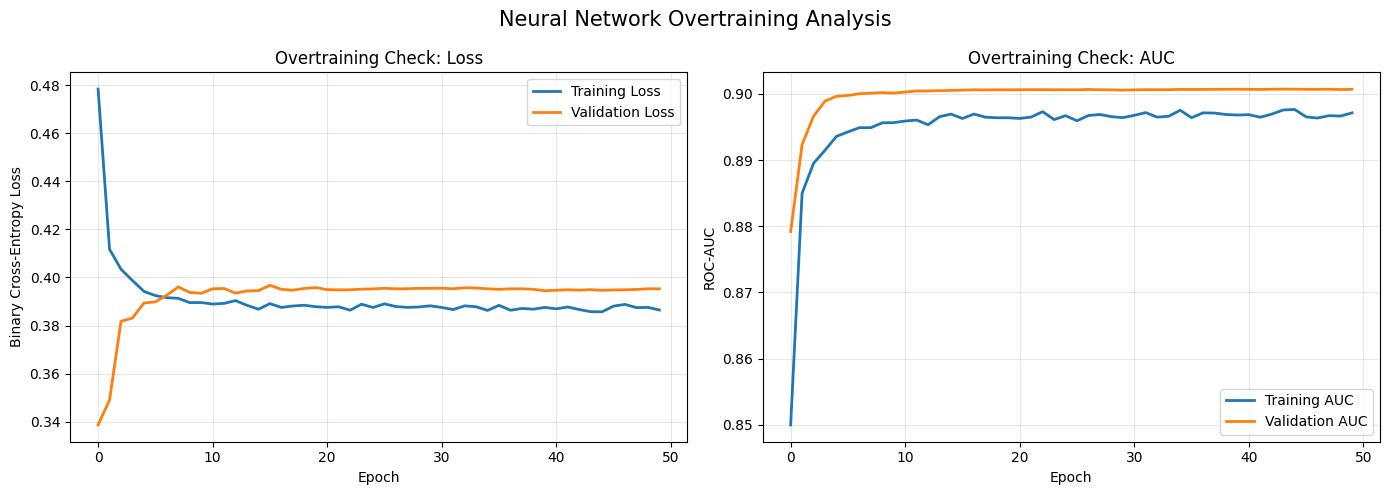

Plot saved: /content/neural_network_overtraining.png


In [36]:

import matplotlib.pyplot as plt

# Check that training history is available
if "history" not in globals():
    raise NameError(
        "Training history is not available. "
        "Run your model.fit() training cell again first."
    )

# Create overtraining plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# =====================================
# 1. Training vs Validation Loss
# =====================================

axes[0].plot(
    history.history["loss"],
    label="Training Loss",
    linewidth=2
)

axes[0].plot(
    history.history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

axes[0].set_title("Overtraining Check: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# =====================================
# 2. Training vs Validation AUC
# =====================================

axes[1].plot(
    history.history["auc"],
    label="Training AUC",
    linewidth=2
)

axes[1].plot(
    history.history["val_auc"],
    label="Validation AUC",
    linewidth=2
)

axes[1].set_title("Overtraining Check: AUC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("ROC-AUC")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle(
    "Neural Network Overtraining Analysis",
    fontsize=15
)

plt.tight_layout()

# Save the graph
plt.savefig(
    "/content/neural_network_overtraining.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Plot saved: /content/neural_network_overtraining.png")


Using predictions: higgs_scores
Number of test events: 451543
Classification threshold: 0.764501


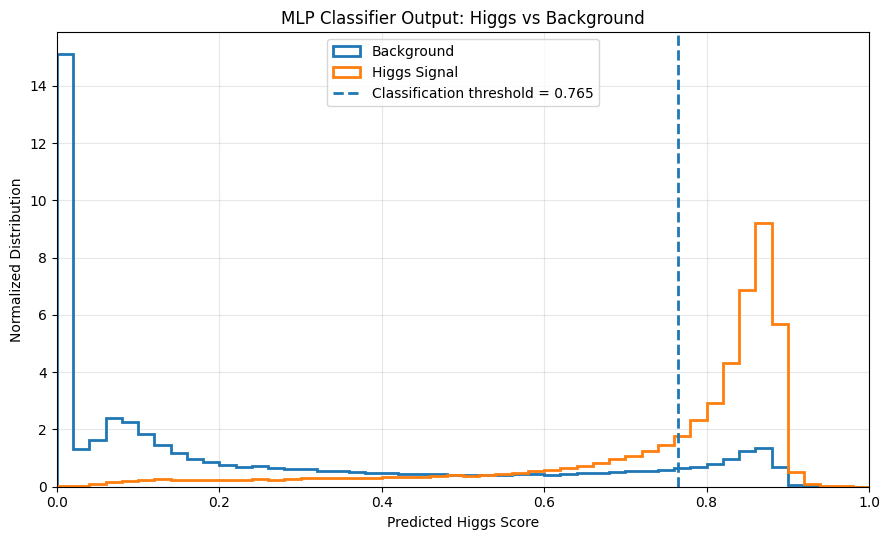

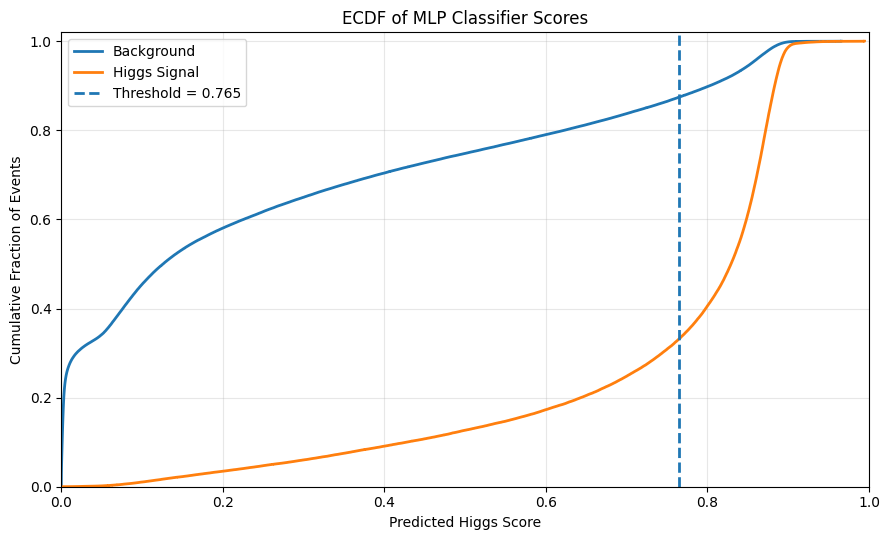


Both plots saved successfully.
MLP output plot: /content/mlp_classifier_output.png
ECDF plot: /content/mlp_classifier_ecdf.png


In [37]:

import os
import json
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. GET THE INDEPENDENT TEST LABELS
# ==========================================

if "y_test_external" in globals():
    y_eval = np.asarray(y_test_external)

elif "y_external" in globals():
    y_eval = np.asarray(y_external)

elif "test_data" in globals() and "label" in test_data.columns:
    y_eval = test_data["label"].to_numpy()

else:
    raise NameError(
        "Test labels are unavailable. Run the independent "
        "test data-loading cell first."
    )


# ==========================================
# 2. GET MLP CLASSIFIER SCORES
# ==========================================

# Reuse predictions from your independent test.
score_variable = None

for name in ["scores", "higgs_scores", "test_scores"]:
    if name in globals():
        candidate = np.asarray(globals()[name]).ravel()

        if len(candidate) == len(y_eval):
            score_variable = name
            mlp_scores = candidate
            break

# If scores are not available, predict using existing
# scaled test features.
if score_variable is None:

    for name in [
        "X_test_external_scaled",
        "X_external_scaled",
        "X_for_test"
    ]:
        if name in globals():
            X_eval = np.asarray(globals()[name])

            if len(X_eval) == len(y_eval):
                mlp_scores = model.predict(
                    X_eval, verbose=0
                ).ravel()

                score_variable = name + " -> model.predict"
                break

if score_variable is None:
    raise NameError(
        "Could not find predictions matching the test labels. "
        "Run the independent test prediction cell first."
    )

if not np.all(np.isfinite(mlp_scores)):
    raise ValueError("Predicted scores contain invalid values.")

print("Using predictions:", score_variable)
print("Number of test events:", len(mlp_scores))

# ==========================================
# 3. GET THE CLASSIFICATION THRESHOLD
# ==========================================

threshold = None

if "THRESHOLD" in globals():
    threshold = float(THRESHOLD)

elif "best_threshold" in globals():
    threshold = float(best_threshold)

else:
    model_dir = globals().get("MODEL_DIR")

    if model_dir:
        path = os.path.join(
            model_dir, "classification_threshold.json"
        )

        if os.path.isfile(path):
            with open(path, "r") as f:
                threshold = float(json.load(f)["threshold"])

if threshold is None:
    threshold = 0.764501

print("Classification threshold:", round(threshold, 6))

# Keep the actual class labels
background_scores = mlp_scores[y_eval == 0]
higgs_scores = mlp_scores[y_eval == 1]

if len(background_scores) == 0 or len(higgs_scores) == 0:
    raise ValueError(
        "Both Higgs and background events are required."
    )

# ==========================================
# 4. PLOT 1: MLP CLASSIFIER OUTPUT
# ==========================================

fig, ax = plt.subplots(figsize=(9, 5.5))

bins = np.linspace(0, 1, 51)

ax.hist(
    background_scores,
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2,
    label="Background"
)

ax.hist(
    higgs_scores,
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2,
    label="Higgs Signal"
)

ax.axvline(
    threshold,
    linestyle="--",
    linewidth=2,
    label=f"Classification threshold = {threshold:.3f}"
)

ax.set_title("MLP Classifier Output: Higgs vs Background")
ax.set_xlabel("Predicted Higgs Score")
ax.set_ylabel("Normalized Distribution")
ax.set_xlim(0, 1)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "/content/mlp_classifier_output.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


# ==========================================
# 5. PLOT 2: EMPIRICAL CUMULATIVE
#    DISTRIBUTION FUNCTION (ECDF)
# ==========================================

def ecdf(values):
    sorted_values = np.sort(values)
    cumulative_fraction = (
        np.arange(1, len(sorted_values) + 1)
        / len(sorted_values)
    )
    return sorted_values, cumulative_fraction


background_x, background_y = ecdf(background_scores)
higgs_x, higgs_y = ecdf(higgs_scores)

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.step(
    background_x,
    background_y,
    where="post",
    linewidth=2,
    label="Background"
)

ax.step(
    higgs_x,
    higgs_y,
    where="post",
    linewidth=2,
    label="Higgs Signal"
)

ax.axvline(
    threshold,
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {threshold:.3f}"
)

ax.set_title("ECDF of MLP Classifier Scores")
ax.set_xlabel("Predicted Higgs Score")
ax.set_ylabel("Cumulative Fraction of Events")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "/content/mlp_classifier_ecdf.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("\nBoth plots saved successfully.")
print("MLP output plot: /content/mlp_classifier_output.png")
print("ECDF plot: /content/mlp_classifier_ecdf.png")


Pearson Correlation Matrix:


,mth,mtw2,ptll,PuppiMET_pt,mll,Lepton1_pt,njet,jet_cat
mth,1.0000,0.4810,0.6055,0.5808,0.1671,0.4526,0.1174,0.1238
mtw2,0.4810,1.0000,0.3570,0.4832,0.2372,0.2783,0.2026,0.2126
ptll,0.6055,0.3570,1.0000,0.4684,0.2113,0.7577,0.4429,0.4397
PuppiMET_pt,0.5808,0.4832,0.4684,1.0000,0.1099,0.3520,0.3973,0.3899
mll,0.1671,0.2372,0.2113,0.1099,1.0000,0.6505,0.0803,0.0781
Lepton1_pt,0.4526,0.2783,0.7577,0.3520,0.6505,1.0000,0.3244,0.3180
njet,0.1174,0.2026,0.4429,0.3973,0.0803,0.3244,1.0000,0.9503
jet_cat,0.1238,0.2126,0.4397,0.3899,0.0781,0.3180,0.9503,1.0000


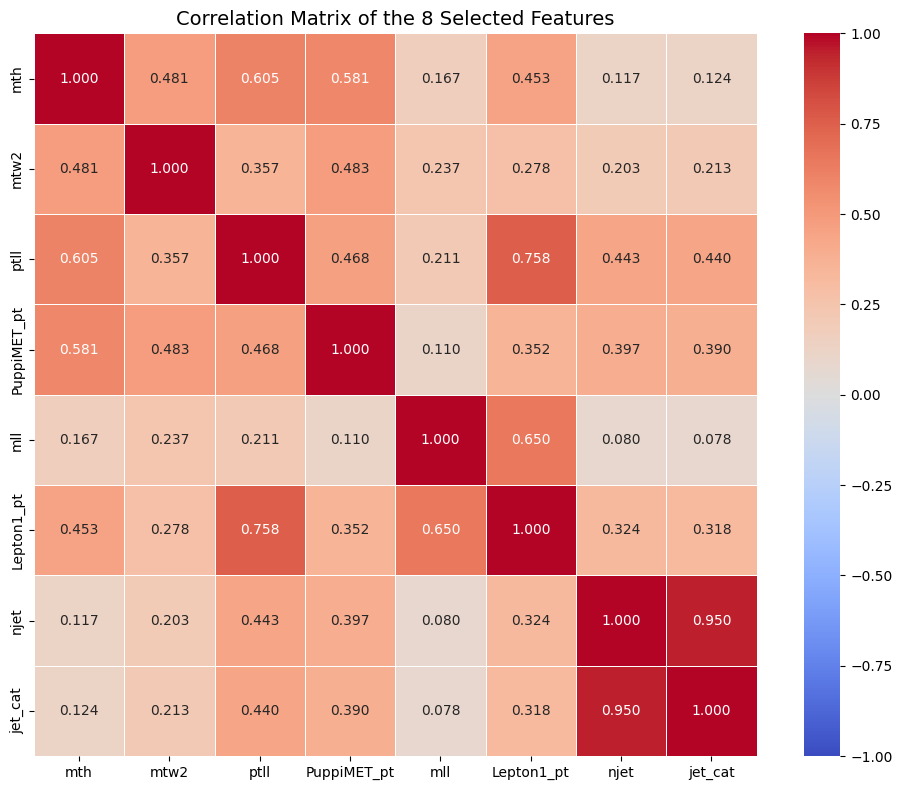

In [39]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import IPython.display

# 1. Create a DataFrame from the feature matrix X and the feature names
feature_df = pd.DataFrame(X, columns=FEATURES)

# 2. Compute the Pearson correlation matrix
corr_matrix = feature_df.corr()

# 3. Display the raw correlation matrix
print("Pearson Correlation Matrix:")
IPython.display.display(corr_matrix.round(4))

# 4. Plot the correlation matrix as a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)
plt.title("Correlation Matrix of the 8 Selected Features", fontsize=14)
plt.tight_layout()
plt.show()